In [1]:
# Imports

import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Define constants

T = 4.0 # Temp [MeV]
m_p = 938.272 # mass of proton [MeV/c^2]
lamda = 197.326 * (2 * np.pi/(m_p * T))**(1/2) # nucleon thermal wavelength [fm^-1] assuming m_p=m_n
lamda_alpha = lamda / 2 # alpha particle thermal wavelength [fm^-1]
E_alpha = 28.3 # alpha particle binding energy [MeV]

# virial coefficients for T = 4 MeV
b_n = 0.307
b_pn = 3.19
b_nuc = 3.50
b_alpha_n = 2.73
b_alpha = 7.44

In [3]:
# Calculate fugacities

z = np.linspace(0, 0.05, 100) # range of nucleon fugacities
z_alpha = z**4 * np.exp(E_alpha/T) # alpha particle fugacity

In [ ]:
# Calculate number densities

#------------------------------
# free n, p, alpha gas
#------------------------------
n_1 = (4/lamda**3) * z # nucleon number density
n_alpha_1 = (1/lamda_alpha**3) * z_alpha # alpha particle number density
n_b_1 = (n_1 + 4 * n_alpha_1) # baryon number density [fm^-3]

#------------------------------
# with b_n, b_pn, b_nuc
#------------------------------
n_2 = (4/lamda**3) * (z + (2 * z**2 * b_nuc))
n_alpha_2 = n_alpha_1
n_b_2 = (n_2 + 4 * n_alpha_2)

#-----------------------------
# with b_alpha_n
#-----------------------------
n_3 = (4/lamda**3) * (z + (2 * z**2 * b_nuc) + (8 * z_alpha * z * b_alpha_n))
n_alpha_3 = (1/lamda_alpha**3) * (z_alpha + (4 * z_alpha * z * b_alpha_n))
n_b_3 = (n_3 + 4 * n_alpha_3)

#----------------------------
# with b_alpha
#----------------------------
n_4 = n_3
n_alpha_4 = (1/lamda_alpha**3) * (z_alpha + (4 * z_alpha * z * b_alpha_n) + (2 * z_alpha**2 * b_alpha))
n_b_4 = (n_4 + 4 * n_alpha_4)

In [5]:
# Calculate alpha mass fractions


x_alpha_1 = 4 * n_alpha_1 / n_b_1 # alpha mass fraction
x_alpha_2 = 4 * n_alpha_2 / n_b_2 # alpha mass fraction
x_alpha_3 = 4 * n_alpha_3 / n_b_3 # alpha mass fraction
x_alpha_4 = 4 * n_alpha_4 / n_b_4 # alpha mass fraction


/var/folders/d6/c6w97l714b14c65394gp4jz80000gn/T/ipykernel_68398/1687802493.py:4: RuntimeWarning: invalid value encountered in divide
  x_alpha_1 = 4 * n_alpha_1 / n_b_1 # alpha mass fraction
/var/folders/d6/c6w97l714b14c65394gp4jz80000gn/T/ipykernel_68398/1687802493.py:5: RuntimeWarning: invalid value encountered in divide
  x_alpha_2 = 4 * n_alpha_2 / n_b_2 # alpha mass fraction
/var/folders/d6/c6w97l714b14c65394gp4jz80000gn/T/ipykernel_68398/1687802493.py:6: RuntimeWarning: invalid value encountered in divide
  x_alpha_3 = 4 * n_alpha_3 / n_b_3 # alpha mass fraction
/var/folders/d6/c6w97l714b14c65394gp4jz80000gn/T/ipykernel_68398/1687802493.py:7: RuntimeWarning: invalid value encountered in divide
  x_alpha_4 = 4 * n_alpha_4 / n_b_4 # alpha mass fraction


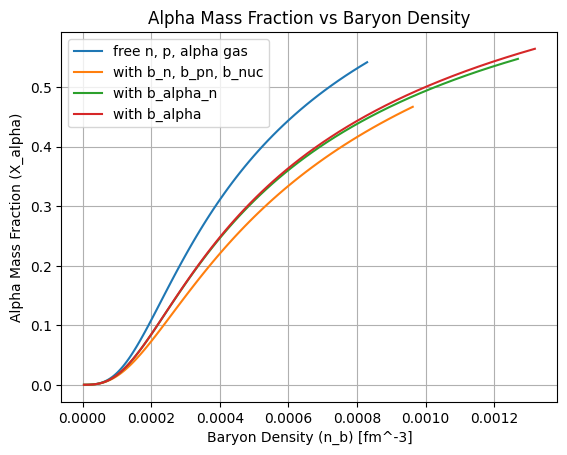

In [6]:
# Plot results

plt.plot(n_b_1, x_alpha_1, label='free n, p, alpha gas')
plt.plot(n_b_2, x_alpha_2, label='with b_n, b_pn, b_nuc')
plt.plot(n_b_3, x_alpha_3, label='with b_alpha_n')
plt.plot(n_b_4, x_alpha_4, label='with b_alpha')
plt.xlabel('Baryon Density (n_b) [fm^-3]')
plt.ylabel('Alpha Mass Fraction (X_alpha)')
plt.title('Alpha Mass Fraction vs Baryon Density')
plt.grid()
plt.legend()
plt.show()
